# Trajektori — Feature GPS dan Klasifikasi Moda Transport
**Kapan dipakai:** data berupa titik GPS (lat, lon, waktu) per perjalanan dan targetnya per
perjalanan (moda transport, jenis kendaraan, perilaku pengemudi).

**Idenya:** titik mentah tidak bisa langsung masuk model. Hitung dulu jarak antar titik,
kecepatan, percepatan, belokan, dan titik berhenti, lalu ringkas jadi **satu baris per
perjalanan** (rata-rata, maksimum, persentil) → LightGBM.

**Langkah:**
1. Feature per titik (jarak haversine, kecepatan, percepatan, belokan, berhenti).
2. Ringkas jadi satu baris per perjalanan.
3. Validasi per pengguna (GroupKFold), latih ulang, submission.

**Data demo:** potongan GeoLife (Beijing), 5 moda: jalan, sepeda, bus, mobil, kereta.
Orang yang sama tidak ada di latih dan test.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import GroupKFold, cross_val_predict

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/trajektori/geolife_mini"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/gps_latih.csv"
TEST_CSV = f"{DATA_FOLDER}/gps_test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/gps_test_labels.csv"   # hanya ada di data latihan

TRIP_COL = "trip_id"      # satu nilai = satu perjalanan
USER_COL = "user"         # untuk validasi per pengguna
TIME_COL = "waktu"
TARGET = "moda"
EARTH_RADIUS_M = 6371000
STOP_SPEED = 0.5          # kecepatan di bawah ini (m/s) dianggap berhenti
SHARP_TURN = 45           # perubahan arah di atas ini (derajat) dianggap belokan tajam
MAX_SPEED = 70            # di atas ini (m/s) dianggap GPS loncat dan dibuang
SEED = 42

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV, dtype={USER_COL: str}, parse_dates=[TIME_COL])
test = pd.read_csv(TEST_CSV, dtype={USER_COL: str}, parse_dates=[TIME_COL])
print(train.shape, test.shape)
print(train.groupby(TARGET)[TRIP_COL].nunique())
train.head()

(70089, 6) (100439, 5)
moda
bus       71
jalan     92
kereta    64
mobil     50
sepeda    77
Name: trip_id, dtype: int64


,trip_id,user,waktu,lat,lon,moda
0,010_101,010,2008-08-01 15:19:04,34.687506,112.430433,kereta
1,010_101,010,2008-08-01 15:19:05,34.687506,112.430463,kereta
2,010_101,010,2008-08-01 15:19:10,34.687525,112.430620,kereta
3,010_101,010,2008-08-01 15:19:15,34.687510,112.430776,kereta
4,010_101,010,2008-08-01 15:19:20,34.687531,112.430978,kereta


## Langkah 1a — jarak, kecepatan, percepatan
Train dan test digabung supaya feature dibuat sekali. Titik "sebelumnya" = `shift(1)` di dalam
tiap perjalanan.

In [4]:
def haversine_m(lat1, lon1, lat2, lon2):
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)
    inner = (np.sin((lat2 - lat1) / 2) ** 2
             + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * EARTH_RADIUS_M * np.arcsin(np.sqrt(inner))


# coba: Monas ke Bundaran HI, sekitar 2.200 m
print(round(haversine_m(-6.1754, 106.8272, -6.1950, 106.8231)), "m")

points = pd.concat([train, test], ignore_index=True)
points = points.sort_values([TRIP_COL, TIME_COL])
per_trip = points.groupby(TRIP_COL)
points["prev_lat"] = per_trip["lat"].shift(1)
points["prev_lon"] = per_trip["lon"].shift(1)
points["distance_m"] = haversine_m(points["prev_lat"], points["prev_lon"],
                                   points["lat"], points["lon"])
points["seconds"] = per_trip[TIME_COL].diff().dt.total_seconds()
points["speed"] = points["distance_m"] / points["seconds"]

# buang titik dengan selisih waktu 0 atau loncatan GPS yang mustahil
points = points[(points["seconds"] > 0) & (points["speed"] < MAX_SPEED)].copy()
per_trip = points.groupby(TRIP_COL)
points["acceleration"] = per_trip["speed"].diff() / points["seconds"]
points["acceleration_abs"] = points["acceleration"].abs()

2226 m


## Langkah 1b — arah, belokan, berhenti
Belokan = perubahan arah antar segmen (0–180 derajat). "Mulai berhenti" = tadi bergerak,
sekarang diam.

In [5]:
lat1 = np.radians(points["prev_lat"])
lat2 = np.radians(points["lat"])
lon_gap = np.radians(points["lon"] - points["prev_lon"])
north = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(lon_gap)
east = np.sin(lon_gap) * np.cos(lat2)
points["heading"] = np.degrees(np.arctan2(east, north))
heading_change = points.groupby(TRIP_COL)["heading"].diff()
heading_change = heading_change.abs()
points["turn"] = np.minimum(heading_change, 360 - heading_change)
points["is_sharp_turn"] = (points["turn"] > SHARP_TURN).astype(int)

points["is_stop"] = (points["speed"] < STOP_SPEED).astype(int)
stop_before = points.groupby(TRIP_COL)["is_stop"].shift(1)
points["stop_start"] = ((points["is_stop"] == 1) & (stop_before == 0)).astype(int)
points[["distance_m", "speed", "acceleration", "turn"]].describe()

,distance_m,speed,acceleration,turn
count,169684.000000,169684.000000,168884.000000,168884.000000
mean,44.001166,6.761009,0.009227,22.595062
std,195.301544,7.706820,0.590391,36.422992
min,0.000000,0.000000,-23.977444,0.000000
25%,6.286526,1.264950,-0.123566,1.944125
50%,18.860392,3.665940,-0.002125,7.285351
75%,55.805415,10.534448,0.126956,24.367542
max,42064.188154,68.231844,52.570818,180.000000


## Langkah 2 — satu baris per perjalanan

In [6]:
per_trip = points.groupby(TRIP_COL)
features = pd.DataFrame()
features["distance_km"] = per_trip["distance_m"].sum() / 1000
features["duration_min"] = per_trip["seconds"].sum() / 60
features["n_points"] = per_trip["seconds"].count()
features["speed_mean"] = per_trip["speed"].mean()
features["speed_median"] = per_trip["speed"].median()
features["speed_std"] = per_trip["speed"].std()
features["speed_max"] = per_trip["speed"].max()
features["speed_p85"] = per_trip["speed"].quantile(0.85)
features["accel_abs_mean"] = per_trip["acceleration_abs"].mean()
features["accel_std"] = per_trip["acceleration"].std()
features["turn_mean"] = per_trip["turn"].mean()
features["sharp_turns_per_km"] = per_trip["is_sharp_turn"].sum() / features["distance_km"]
features["stop_share"] = per_trip["is_stop"].mean()
features["n_stops"] = per_trip["stop_start"].sum()
features = features.fillna(0)

features["mode"] = per_trip[TARGET].first()        # kosong untuk trip test
features["user"] = per_trip[USER_COL].first()
print(features.shape)
features.head()

(800, 16)


,distance_km,duration_min,n_points,speed_mean,speed_median,speed_std,speed_max,speed_p85,accel_abs_mean,accel_std,turn_mean,sharp_turns_per_km,stop_share,n_stops,mode,user
trip_id,,,,,,,,,,,,,,,,
010_101,64.840860,40.850000,487,26.433415,25.226440,8.685989,38.840019,36.958761,0.096817,0.160529,3.306741,0.000000,0.000,0,kereta,010
010_103,3.097005,8.333333,88,6.966428,6.713106,3.619478,13.940611,10.995750,0.311993,0.406846,15.527998,1.937356,0.000,0,bus,010
010_114,4.977560,9.416667,96,10.347388,10.110181,6.596526,24.355732,17.603766,0.443083,0.736147,20.630441,3.013525,0.125,4,mobil,010
010_121,36.101273,19.316667,209,34.481430,35.352191,17.584966,66.850365,55.606877,0.296720,0.485902,2.934390,0.000000,0.000,0,kereta,010
010_142,22.097262,11.500000,139,32.034919,26.750951,17.904542,67.097913,54.807052,0.207558,0.266508,3.375762,0.000000,0.000,0,kereta,010


## Langkah 3a — model + validasi per pengguna (GroupKFold)
Pilih SATU model: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.

In [7]:
train_features = features[features["mode"].notna()]
test_features = features[features["mode"].isna()]
X = train_features.drop(columns=["mode", "user"])
y = train_features["mode"]
groups = train_features["user"]
X_test = test_features.drop(columns=["mode", "user"])

model = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=5,
                       subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                       random_state=SEED, verbose=-1, n_jobs=4)
# model = RandomForestClassifier(n_estimators=500, min_samples_leaf=2, random_state=SEED,
#                                n_jobs=4)

oof_predictions = cross_val_predict(model, X, y, cv=GroupKFold(5), groups=groups)
print("F1 macro GroupKFold:", round(f1_score(y, oof_predictions, average="macro"), 4))
print(classification_report(y, oof_predictions))

F1 macro GroupKFold: 0.6602
              precision    recall  f1-score   support

         bus       0.68      0.75      0.71        71
       jalan       0.84      0.88      0.86        92
      kereta       0.65      0.41      0.50        64
       mobil       0.31      0.38      0.34        50
      sepeda       0.88      0.90      0.89        77

    accuracy                           0.70       354
   macro avg       0.67      0.66      0.66       354
weighted avg       0.71      0.70      0.70       354



## Langkah 3b — latih ulang + submission (satu baris per perjalanan)

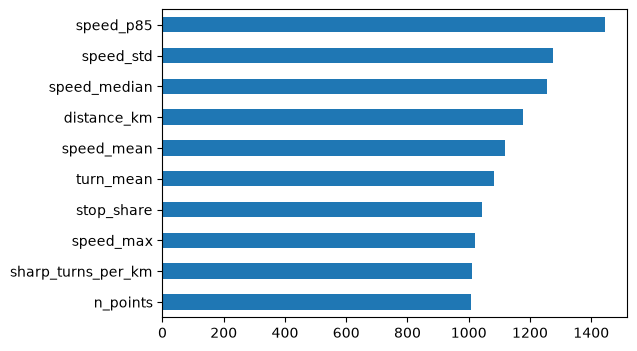

,trip_id,moda
0,052_120,bus
1,052_141,bus
2,052_15,mobil
3,052_160,bus
4,052_169,bus


In [8]:
model.fit(X, y)
importance = pd.Series(model.feature_importances_, index=X.columns)
importance = importance.sort_values()
importance.tail(10).plot.barh(figsize=(6, 4))
plt.show()

predictions = model.predict(X_test)

submission = pd.DataFrame()
submission["trip_id"] = X_test.index
submission["moda"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

## Cek dengan kunci jawaban (HAPUS saat lomba)

F1 macro test: 0.7495


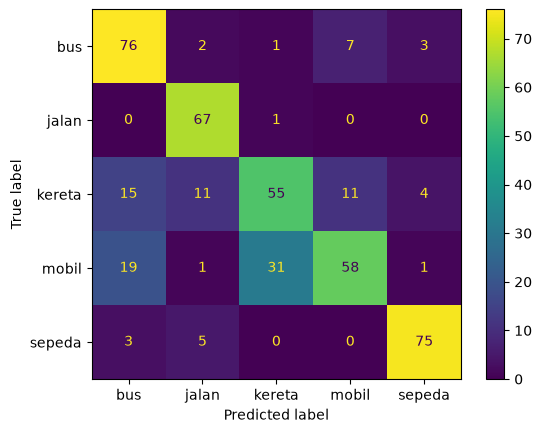

In [9]:
test_key = pd.read_csv(TEST_KEY_CSV)
true_modes = pd.Series(test_key["moda"].to_numpy(), index=test_key["trip_id"])
truth = submission["trip_id"].map(true_modes)
print("F1 macro test:", round(f1_score(truth, predictions, average="macro"), 4))
ConfusionMatrixDisplay.from_predictions(truth, predictions)
plt.show()